# Imports

In [484]:
import polars as pl
import pandas as pd 
import numpy as np
import os
import pyarrow.dataset as pads

from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score, accuracy_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import export_text
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RepeatedKFold,GridSearchCV,RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score
import itertools
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.preprocessing     import StandardScaler 

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from great_tables import GT
import gt_extras as gte
import seaborn as sns

# Read in Data

In [ ]:
def readDataSubset(table_type, data_path = f""):
    if table_type not in ["ball-positions", "ball-events", "player-positions", "lineups", "game-info"]:
        print("Nah big dawg use a real dataset")
        return -1
    if table_type =='lineups' or table_type == 'game-info':
        return pads.dataset(source = os.path.join(os.path.dirname(__name__), data_path, table_type + '.csv'), format = 'csv')
    else:
        return pads.dataset(source = os.path.join(os.path.dirname(__name__), data_path, table_type), format = 'csv', partitioning = ['home_team', 'away_team', 'year', 'day'])

In [486]:
# Read in Ball Events Data
ball_events_subset = readDataSubset("ball-events")
ball_events = ball_events_subset.to_table().to_pandas()
ball_events_df = pl.from_pandas(ball_events)

# Read in Lineups Data
lineups_subset = readDataSubset('lineups')
lineups = lineups_subset.to_table().to_pandas()
lineups_df = pl.from_pandas(lineups)

# Read in Player Position for Second Baseman (4)
player_pos_subset = readDataSubset('player-positions')
player_pos_04 = player_pos_subset.to_table(filter = ((pads.field("player_id") == 4))).to_pandas()
player_pos_04_df = pl.from_pandas(player_pos_04)

# Read in Player Position for Shortstop (6)
player_position_06 = player_pos_subset.to_table(filter = ((pads.field("player_id") == 6))).to_pandas()
player_position_06_df = pl.from_pandas(player_position_06)

# Read in Player Position for Runner on 1B (11)
player_position_11 = player_pos_subset.to_table(filter = ((pads.field("player_id") == 11))).to_pandas()
player_position_11_df = pl.from_pandas(player_position_11)

# read in Player Position for Runner on 2B (12)
player_pos_12 = player_pos_subset.to_table(filter = ((pads.field("player_id") == 12))).to_pandas()
player_pos_12_df = pl.from_pandas(player_pos_12)

# Stolen Base Model

- build a model based on the odds of a player stealing second base when on first
    - features include
        - Defensive Positioning (2BM & SS)
        - Ball Location
    - Output would be if he should steal or not (Red Light Green Light)
        - Testing Linear Regression, Decision Tree, Random Forest

**First** Build a Model focusing on 2nd baseman and SS positions and the odss to steal based on that. 

- lets first clean our player_pos_df adding in player timestamp and field positioning for 2BM, SS, Runner 1 (R1), Runner 2 (R2)

- This will be used to find when a steal happened by seeing when a runner moved from 1b to 2b but batter remains the same

## Player_Position Setup

In [487]:
# Clean player_pos_04_df adding in a new column for 2BM time and field
clean_2bm_df = player_pos_04_df.sort(
    # sort to make sure games are in order
    ["game_string", "play_per_game", "timestamp"]
).select(
    # Select only columns we need while adding in new 2BM_field_x/y and 2BM_timestamp
    [
        "game_string", "play_per_game", pl.col("timestamp").alias("2bm_timestamp"),
        pl.col("field_x").alias("2bm_field_x"), pl.col("field_y").alias("2bm_field_y")
    ]
)

# Clean player_pos_06_df adding in a new column for ss time and field
clean_ss_df = player_position_06_df.sort(
    # sort to make sure games are in order
    ["game_string", "play_per_game", "timestamp"]
).select(
    # Select only column we need while adding in new ss_field_x/y and ss_timestamp
    [
        "game_string", "play_per_game", pl.col("timestamp").alias("ss_timestamp"),
        pl.col("field_x").alias("ss_field_x"), pl.col("field_y").alias("ss_field_y")
    ]
)

# Clean player_pos_11_df adding in a new column for R1 time and field
clean_r1_df = player_position_11_df.sort(
    # sort to make sure games are in order
    ["game_string", "play_per_game", "timestamp"]
).select(
    # Select only column we need while adding in new r1_field_x/y and r1_timestamp
    [
        "game_string", "play_per_game", pl.col("timestamp").alias("r1_timestamp"),
        pl.col("field_x").alias("r1_field_x"), pl.col("field_y").alias("r1_field_y")
    ]
)

# Clean player_pos_12_df adding in a new column for R2 time and field
clean_r2_df = player_pos_12_df.sort(
    # sort to make sure games are in order
    ["game_string", "play_per_game", "timestamp"]
).select(
    # Select only column we need while adding in nre r2_field_x/y and r2_timestamp
    [
        "game_string", "play_per_game", pl.col("timestamp").alias("r2_timestamp"),
        pl.col("field_x").alias("r2_field_x"), pl.col("field_y").alias("r2_field_y")
    ]
)

#print(clean_2bm_df.shape)
#print(clean_ss_df.shape)
#print(clean_r1_df.shape)
#print(clean_r2_df.shape)

Using `.shape` we can see how many rows of data we have for each of our datasets. 
- 2bm = `7,617,758`
- ss = `7,618,094`
- R1 = `2,681,968`
- R2 = `1,659,804`

Seems like a lot but there is multiple posisitons per game_events so we need to condence these down to 1 player_pos per game_event using `.agg()` and using the mean

- We also only need the datapoints where there is a runner on 1 dropping alot of the rows

In [488]:
# concat our dfs together into one df
player_position_df = pl.concat(
    [clean_2bm_df, clean_ss_df, clean_r1_df, clean_r2_df],
    how = "diagonal" # diagonal takes all columns, fills mismatch with null, columns must match
).group_by(
    # groups rows by game_string and play_per_game
    ["game_string", "play_per_game"]
).agg( # aggregating the results finding the average location and time of players during steal window
    # 2BM
    pl.col("2bm_timestamp").min().alias("2bm_start_time"),
    pl.col("2bm_timestamp").max().alias("2bm_end_time"),
    pl.col("2bm_field_x").min().alias("2bm_start_x"),
    pl.col("2bm_field_x").max().alias("2bm_end_x"),
    pl.col("2bm_field_y").min().alias("2bm_start_y"),
    pl.col("2bm_field_y").max().alias("2bm_end_y"),

    # SS
    pl.col("ss_timestamp").mean(),
    pl.col("ss_field_x").mean(),
    pl.col("ss_field_y").mean(),

    # Runner 1
    pl.col("r1_timestamp").mean(),
    pl.col("r1_field_x").mean(),
    pl.col("r1_field_y").mean(),

    # Runner 2
    pl.col("r2_timestamp").mean(),
    pl.col("r2_field_x").mean(),
    pl.col("r2_field_y").mean()
).with_columns(
    # adding a on_1b and on_2b so we know if there is somewhere there
    (pl.col("r1_field_x")).alias("on_1b"),
    (pl.col("r2_field_x")).alias("on_2b"),
).with_columns(
    # turn player per game to int64 for easier joining
    play_per_game = pl.col("play_per_game").cast(pl.Int64),

    # turn on_1b and on_2b to a boolean true/false
    on_1b = pl.col("on_1b").cast(pl.Boolean),
    on_2b = pl.col("on_2b").cast(pl.Boolean)
).with_columns(
    # fill on_1b and on_2b with True/False so we can isolate when steals happen
    # when 1b or 2b is empty put False if occupied put True
    on_1b = pl.when(pl.col("on_1b").is_null()).then(pl.lit(False)).otherwise(pl.lit(True)),
    on_2b = pl.when(pl.col("on_2b").is_null()).then(pl.lit(False)).otherwise(pl.lit(True))
).select(
    # select all needed columns
    [
        "game_string", "play_per_game", 
        "2bm_start_time", "2bm_start_x", "2bm_start_y",
        "2bm_end_time", "2bm_end_x", "2bm_end_y",
        "r1_timestamp", "r1_field_x", "r1_field_y",
        "r2_timestamp", "r2_field_x", "r2_field_y",
        "on_1b", "on_2b"
    ]
).sort(
    # Finally sort columns so they are in order
    ["game_string", "play_per_game"]
)

# player_position_df.shape

after condensing everything down we are left with only `74,043` rows of data.

Our next step is to read in our lineups dataframe for the person at_bat. We will use him to make sure a steal happens and is not movement from a hit. 

The idea is to find when a runner on 1 moves to second put the person at bat is the same 

We will use this to make out steal dataframe

## Lineups for steal df using at_bat

In [489]:
# We only want to read in games from our player_postiion_df that we made earlier

relevant_game_string = player_position_df["game_string"] # saves only game_strings from this dataframe
relevant_ppg = player_position_df["play_per_game"] # saves only play_per_game from this dataframe

# Read in lineups data
lineups_subset = readDataSubset("lineups")
lineups = lineups_subset.to_table(filter = ((pads.field("game_string").isin(relevant_game_string)) & 
                                            (pads.field("play_per_game").isin(relevant_ppg)))).to_pandas()
lineups_df = pl.from_pandas(lineups)

# we only want the at_bat data
lineups_df = lineups_df.select(
    ["game_string", "play_per_game", "at_bat"]
)

In [490]:
# Now we join our player_position_df with lineups_df to make the steal_df
steals_df = player_position_df.join(
    lineups_df,
    on = ["game_string", "play_per_game"], # matching these columns when joining
    how = "left" # new df will join on the left
).sort(
    # always sort to make sure they are in order
    ["game_string", "play_per_game"]
).select(
    # Select only needed columns
    [
        "game_string", "play_per_game", 
        "2bm_start_time", "2bm_start_x", "2bm_start_y",
        "2bm_end_time", "2bm_end_x", "2bm_end_y",
        "r1_timestamp", "r1_field_x", "r1_field_y",
        "r2_timestamp", "r2_field_x", "r2_field_y",
        "on_1b", "on_2b", "at_bat"
    ]
)

In [491]:
# now we can make our successful_steals_df
successful_steals = steals_df.with_columns(
    # add column for next at bat
    (pl.col("at_bat").shift(-1)).alias("next_at_bat"),

    # add column for next on first base
    (pl.col("on_1b").shift(-1)).alias("next_on_1b"),

    # add column for Next on second base
    (pl.col("on_2b").shift(-1)).alias("next_on_2b"),

    # add column so we can track R1 moving to R2
    (pl.col("r2_timestamp").shift(-1)).alias("next_time"),
    (pl.col("r2_field_x").shift(-1)).alias("next_x"),
    (pl.col("r2_field_y").shift(-1)).alias("next_y")
).filter(
    # Filter so that its the same person at bat
    (pl.col("at_bat") == pl.col("next_at_bat")) &

    # AND filter for someone being on first base
    (pl.col("on_1b") == True) &

    # AND filter for no one being on second base
    (pl.col("on_2b") == False) &

    # AND also filter for the next play first base being empty
    (pl.col("next_on_1b") == False) &

    # And also filter for the next play having someone on second base
    (pl.col("next_on_2b") == True)
).with_columns(
    # New column labling this dataframe as sucessful steal (1)
    (pl.lit(1).alias("steal_successful"))
)

#print(successful_steals.shape)

now that we have separated successful steals from our steals dataframe we are left with `347` rows of usable data

Next we well find the failed steals

In [492]:
# start making the failed steal dataframe
failed_steals = steals_df.with_columns(
    # add column for next at bat
    (pl.col("at_bat").shift(-1)).alias("next_at_bat"),

    # add column for next on first base
    (pl.col("on_1b").shift(-1)).alias("next_on_1b"),

    # add column for next on second base
    (pl.col("on_2b").shift(-1)).alias("next_on_2b"),

    (pl.col("r2_timestamp").shift(-1)).alias("next_time"),
    (pl.col("r2_field_x").shift(-1)).alias("next_x"),
    (pl.col("r2_field_y").shift(-1)).alias("next_y")
).filter(
    # Filter so that its the same person at_bat
    (pl.col("at_bat") == pl.col("next_at_bat")) &

    # And filter for someone being on first base
    (pl.col("on_1b") == True) &

    # And filter for no one being on second base
    (pl.col("on_2b") == False) &

    # And filter for no one being on first base next pitch
    (pl.col("next_on_1b") == False) &

    # AND filter for no one being on second base next pitch
    (pl.col("next_on_2b") == False)
).with_columns(
    # label this column (0) so that we know these are failed
    (pl.lit(0)).alias("steal_successful")
)

#print(failed_steals.shape)

Now that we separated failed steals we are left with `183` rows for failed steals

Next we join these two datasets together

In [493]:
final_steals_df = pl.concat([successful_steals, failed_steals], how = "vertical").sort(
    # sort to keep events in order
    ["game_string", "play_per_game"]
)

print(final_steals_df.shape)

(530, 24)


for our final steal dataframe we are left with `530` usable rows of data split between successful and failed steals

Next we are going to make a new dataframe but adding in Catcher and if he threw to SS or 2bm

## Catcher to Shortstop or maybe Second Baseman

Look for squence where ball is put into play but catcher throws to 2nd base

|player_id|event_code|
|-----|-----|
|1 (Pitcher)|1 (pitch)|
|2 (Catcher)|2 (ball acquired)|
|2 (Cather) |3 (Throw)|
|4 (Second BM)| 2 (ball acquired)

In [494]:
# make a catcher events df to second baseman using ball_events
catcher_events_2bm = ball_events_df.sort(
    # Sort so data is in order
    ["game_string", "play_per_game", "timestamp"]
).filter(
    # Filter for pitch first 
    (pl.col("player_id") == 1) & # player_id == 1 for pitcher
    (pl.col("ball_eventcode") == 1) & # ball_eventcode == 1 for pitch

    # Filter down for catcher getting ball then throwing it 
    (pl.col("player_id").shift(-1) == 2) & # player_id == 2 for catcher shift to next play
    (pl.col("ball_eventcode").shift(-1) == 2) & # ball_eventcode == 2 for ball acquired shift to next play
    (pl.col("player_id").shift(-2) == 2) & # player_id == 2 for catcher shift to next next play
    (pl.col("ball_eventcode").shift(-2) == 3) & # ball_eventcode == 3 for throw shift to next next play

    # Filter to second baseman making catch
    (pl.col("player_id").shift(-3) == 4) & # player_id == 4 for 2bm shift to next next next play
    (pl.col("ball_eventcode").shift(-3) == 2) # ball_eventcode == 2 for ball acquired for next next next play
    .over(["game_string", "play_per_game"])
).select(
    # select only needed columns
    [
        "game_string", "play_per_game",
        pl.col("timestamp").alias("throw_time"), # change timestamp to throwtime
        pl.lit("4").alias("who_caught_it") # make a column for who caught the ball
    ]
)

#print(catcher_events_2bm.shape)

left with 85 rows where catcher threw to second base man

In [495]:
# same df but in reverser order so that we have a catch time
ball_events_2bm = ball_events_df.sort(
    # sort df
    ["game_string", "play_per_game", "timestamp"]
).filter(
    # Filter for previous play being thrown by catcher
    (pl.col("player_id").shift(1) == 2) & # player_id == 2 for catcher shift to previous play
    (pl.col("ball_eventcode").shift(1) == 3) & # ball_eventcode == 4 for throw shift to previous play

    # Filter to 2bm making catch
    (pl.col("player_id") == 4) & # player_id == 4 for 2bm current play
    (pl.col("ball_eventcode") == 2) # ball_eventcode == 2 for ball acquired
    .over(["game_string", "play_per_game"])
).select(
    [
        "game_string", "play_per_game",
        pl.col("timestamp").alias("catch_time"), # change timestamp to catch_time
        pl.lit("4").alias("who_caught_it")
    ]
)

#print(ball_events_2bm.shape)

Have 93 rows of data where a second baseman makes a catch from catcher

In [496]:
# now a dataframe put catcher throwing to shortstop
catcher_events_ss = ball_events_df.sort(
    # make sure games are in order
    ["game_string", "play_per_game", "timestamp"]
).filter(
    # Filter for pitch first
    (pl.col("player_id") == 1) & # player_id == 1 for pitcher
    (pl.col("ball_eventcode") == 1) & # ball_eventcode == 1 for pitch

    # Filter for catcher acquiring ball 
    (pl.col("player_id").shift(-1) == 2) & # player_id == 2 for catcher on next event
    (pl.col("ball_eventcode").shift(-1) == 2) & # ball_eventcode == 2 for ball acquired on next event

    # Filter to catcher throwing ball
    (pl.col("player_id").shift(-2) == 2) & # player_id == 2 for catcher on next next event
    (pl.col("ball_eventcode").shift(-2) == 3) & # ball_eventcode == 3 for catcher throwing ball on next next event

    # Filter to SS catching the ball
    (pl.col("player_id").shift(-3) == 6) & # player_id == 6 for ss on next next next event
    (pl.col("ball_eventcode").shift(-3) == 2) # ball_eventcode == 2 for ball acquired on next next next event
    .over(["game_string", "play_per_game"])
).select(
    ["game_string", "play_per_game", pl.col("timestamp").alias("throw_time"), pl.lit("6").alias("who_caught_it")]
)

#print(catcher_events_ss.shape)

Have 88 rows of data where cather threw ball to shortstop

In [497]:
# make a df for ss making catch
ball_events_ss = ball_events_df.sort(
    # Sort dataframe
    ["game_string", "play_per_game", "timestamp"]
).filter(
    # Filter for previous event being catcher throwing ball
    (pl.col("player_id").shift(1) == 2) & # player_id == 2 for catcher previous event
    (pl.col("ball_eventcode").shift(1) == 3) & # ball_eventcode == 3 for ball thrown on previous event

    # Filter for ss making catch
    (pl.col("player_id") == 6) & # player_id == 6 for ss
    (pl.col("ball_eventcode") == 2) # ball_eventcode == 2 for ball acquired
    .over(["game_string", "play_per_game"])
).select(
    ["game_string", "play_per_game", pl.col("timestamp").alias("catch_time"), pl.lit("6").alias("who_caught_it")]
)

#print(ball_events_ss.shape)

Have 100 rows of data where SS caught ball from catcher

In [498]:
# Concat the df together making a new df
catcher_steals = pl.concat(
    [catcher_events_2bm, ball_events_2bm, catcher_events_ss, ball_events_ss],
    how = "diagonal"
).group_by(
    # group all events 
    ["game_string", "play_per_game", "who_caught_it"]
).agg(
    # agg the time taking the min
    pl.col("throw_time").min(),
    pl.col("catch_time").min()
).with_columns(
    # turn time into seconds
    throw_time = ((pl.col("catch_time") - pl.col("throw_time")) / 1000).round(2),
    # turn play_per_game into a int64
    play_per_game = pl.col("play_per_game").cast(pl.Int64)
).sort(
    # sort games in order
    ["game_string", "play_per_game"]
).select(
    # select only needed columns
    ["game_string", "play_per_game", "throw_time", "who_caught_it"]
).drop_nulls(
    # drop blank play_per_games
    "play_per_game"
).drop_nulls(
    # fill blank throw_times with zero
    "throw_time"
).fill_null(0)

#print(catcher_steals.shape)

#counts_2bm = catcher_steals.filter(pl.col("who_caught_it") == "2bm")
#print(counts_2bm)

#counts_ss = catcher_steals.filter(pl.col("who_caught_it") == "ss")
#print(counts_ss)

Out of 530 rows in our steals_df we have 172 of them that a catcher threw the ball

- 87 caught by SS
- 85 caught by 2bm

# Adding in 2bm and ss positions. 

Now we want to add in the before add after for who caught the ball in our cather steals df

In [499]:
# load in second baseman pos 
second_baseman_df = player_pos_04_df.sort(
    # Sort to make sure they are in order
    ["game_string", "play_per_game", "timestamp"]
).group_by(
    # group rows
    ["game_string", "play_per_game"]
).agg(
    # agg the results
    pl.col("timestamp").min().alias("start_time"), # using Min to add a start time during the play
    pl.col("timestamp").max().alias("end_time"), # using Max to add a end time during the play
    pl.col("field_x").min().alias("start_x"), # using Min to add a start pos during the play
    pl.col("field_x").max().alias("end_x"), # using Max to add a end pos during the play
    pl.col("field_y").min().alias("start_y"), # using Min to add a start pos during the play
    pl.col("field_y").max().alias("end_y") # using Max to add a end pos during the play
).with_columns(
    # change play_per_game to int64 for easier joining
    play_per_game = pl.col("play_per_game").cast(pl.Int64),
    who_caught_it = pl.lit("4")
).sort(
    # Never hurts to sort again just incase
    ["game_string", "play_per_game"]
)

In [500]:
# Now we are going to do the same thing but for SS
# load in ss pos
shortstop_df = player_position_06_df.sort(
    # Sort to make sure they are in order
    ["game_string", "play_per_game", "timestamp"]
).group_by(
    # group rows
    ["game_string", "play_per_game"]
).agg(
    # agg the results
    pl.col("timestamp").min().alias("start_time"), # using Min to add a start time during the play
    pl.col("timestamp").max().alias("end_time"), # using Max to add a end time during the play
    pl.col("field_x").min().alias("start_x"), # using Min to add a start pos during the play
    pl.col("field_x").max().alias("end_x"), # using Max to add a end pos during the play
    pl.col("field_y").min().alias("start_y"), # using Min to add a start pos during the play
    pl.col("field_y").max().alias("end_y") # using Max to add a end pos during the play
).with_columns(
    # change play_per_game to int64 for easier joining
    play_per_game = pl.col("play_per_game").cast(pl.Int64),
    who_caught_it = pl.lit("6")
).sort(
    # Never hurts to sort again just incase
    ["game_string", "play_per_game"]
)

In [501]:
# we first have to concat are two df together
ss_2bm_pos = pl.concat(
    # our dataframes
    [second_baseman_df, shortstop_df],
    how = "diagonal"
)

In [502]:
# now we join on to our catcher df
updated_pos_df = catcher_steals.join(
    # df that we joining on
    ss_2bm_pos,
    # columns we are joining on
    on = ["game_string", "play_per_game", "who_caught_it"],
    how = "left"
).with_columns(
    # make play_per_game int64
    play_per_game = pl.col("play_per_game").cast(pl.Int64)
).sort(
    # sort to make sure in order
    ["game_string", "play_per_game"]
)

In [503]:
# now we can join this one to make our last_df
maybe_last_df = final_steals_df.join(
    # add df we are joining
    updated_pos_df,
    on = ["game_string", "play_per_game"],
    how = "left"
).with_columns(
    # When joining we are going to have alot of blanks so we are going to fill in some data
    pl.col("start_time").fill_null(pl.col("2bm_start_time")), # Fill in start_time with 2bm time 
    pl.col("end_time").fill_null(pl.col("2bm_end_time")), # fill in end_time with 2bm_time
    pl.col("start_x").fill_null(pl.col("2bm_start_x")), # fill in start_x with 2bm start x
    pl.col("end_x").fill_null(pl.col("2bm_end_x")), # fill in end_x with 2bm end x
    pl.col("start_y").fill_null(pl.col("2bm_start_y")), # fill in start_y with 2bm start y
    pl.col("end_y").fill_null(pl.col("2bm_end_y")), # fill in end_y with 2bm_end_y
    pl.col("who_caught_it").fill_null(0) # fill nulls with 0 for nobody
    # We already have SS data loaded into the df and we are going to assume that the 2bm will cover the blanks 
).with_columns(
    # convert time and change in positions/time

    # runner
    change_time_runner = (pl.col("next_time") - pl.col("r1_timestamp")).over(["game_string", "play_per_game"]),
    change_pos_runner_x = (pl.col("r1_field_x") - pl.col("next_x")).over(["game_string", "play_per_game"]),
    change_pos_runner_y = (pl.col("r1_field_y") - pl.col("next_y")).over(["game_string", "play_per_game"]),

    #defense
    change_time_defense = (pl.col("end_time") - pl.col("start_time")).over(["game_string", "play_per_game"]),
    change_pos_defense_x = (pl.col("end_x") - pl.col("start_x")).over(["game_string", "play_per_game"]),
    change_pos_defense_y = (pl.col("end_y") - pl.col("start_y")).over(["game_string", "play_per_game"])
).with_columns(
    # convert change_time to seconds and calculate distance of covered

    # runner
    change_time_runner_sec = pl.col("change_time_runner") / 1000,
    dcov_step_runner = (pl.col("change_pos_runner_x") ** 2 + pl.col("change_pos_runner_y") ** 2).sqrt().over(["game_string", "play_per_game"]),

    # defense
    change_time_defense_sec = pl.col("change_time_defense") / 1000,
    dcov_step_defense = (pl.col("change_pos_defense_x") ** 2 + pl.col("change_pos_defense_y") ** 2).sqrt().over(["game_string", "play_per_game"])
).with_columns(
    # calculate distance total and running distance

    # runner
    dcov_total_runner = pl.col("dcov_step_runner").sum().over(["game_string", "play_per_game"]),
    dcov_running_runner = pl.col("dcov_step_runner").cum_sum().over(["game_string", "play_per_game"]),

    #defense
    dcov_total_defense = pl.col("dcov_step_defense").sum().over(["game_string", "play_per_game"]),
    dcov_running_defense = pl.col("dcov_step_defense").cum_sum().over(["game_string", "play_per_game"])
).with_columns(
    # calculate insta velo, accel, and jerk for runner
    i_vel_runner = pl.col("dcov_step_runner") / pl.col("change_time_runner_sec"),
    i_accel_runner = (pl.col("dcov_step_runner") / (pl.col("change_time_runner_sec")) ** 2),
    i_jerk_runner = (pl.col("dcov_step_runner") / (pl.col("change_time_runner_sec")) ** 3),

    # calculate insta velo, accel, and jerk for defense
    i_vel_defense = pl.col("dcov_step_defense") / pl.col("change_time_defense_sec"),
    i_accel_defense = (pl.col("dcov_step_defense") / (pl.col("change_time_defense_sec")) ** 2),
    i_jerk_defense = (pl.col("dcov_step_defense") / (pl.col("change_time_defense_sec")) ** 3),
).sort(
    # sort rows
    ["game_string", "play_per_game"]
).select(
    # Only select columns needed for machine learning
    [
        "game_string", "play_per_game", "steal_successful", "who_caught_it", "throw_time",

        # Runner
        pl.col("r1_field_x").alias("runner_x"), pl.col("r1_field_y").alias("runner_y"),
        pl.col("next_x").alias("next_runner_x"), pl.col("next_y").alias("next_runner_y"),
        "change_time_runner_sec", "dcov_step_runner", "dcov_total_runner", "dcov_running_runner",
        "i_vel_runner", "i_accel_runner", "i_jerk_runner",
        
        # Defense
        pl.col("start_x").alias("defense_x"), pl.col("start_y").alias("defense_y"),
        pl.col("end_x").alias("next_defense_x"), pl.col("end_y").alias("next_defense_y"),
        "change_time_defense_sec", "dcov_step_defense", "dcov_total_defense", "dcov_running_defense",
        "i_vel_defense", "i_accel_defense", "i_jerk_defense"
    ]
)

- with this last df we still have all 530 rows of data that involves steals
    - have some nulls in places

- if we drop all nulls and only use data with everything filled we are left with 67 rows of data
    - all those datas are steals being successful

In [504]:
maybe_last_df.sample(10)

game_string,play_per_game,steal_successful,who_caught_it,throw_time,runner_x,runner_y,next_runner_x,next_runner_y,change_time_runner_sec,dcov_step_runner,dcov_total_runner,dcov_running_runner,i_vel_runner,i_accel_runner,i_jerk_runner,defense_x,defense_y,next_defense_x,next_defense_y,change_time_defense_sec,dcov_step_defense,dcov_total_defense,dcov_running_defense,i_vel_defense,i_accel_defense,i_jerk_defense
str,i64,i32,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""y1_d061_VKA_PHD""",106,0,"""4""",2.35,39.55026,88.716391,null,null,null,null,0.0,null,null,null,null,0.2904,123.6849,23.3595,139.5435,6.2,27.99426,27.99426,27.99426,4.515203,0.728259,0.117461
"""y1_d083_NXS_ARN""",227,1,"""0""",null,35.649044,92.105487,-32.787025,104.170013,33.125,69.491354,69.491354,69.491354,2.097852,0.063331,0.001912,50.9358,138.6147,52.3725,142.6689,6.15,4.301238,4.301238,4.301238,0.699388,0.113722,0.018491
"""y1_d098_NYN_ARN""",10,0,"""0""",null,52.822737,76.278921,null,null,null,null,0.0,null,null,null,null,51.3771,126.9951,53.1777,129.3495,3.55,2.964011,2.964011,2.964011,0.834933,0.235192,0.066251
"""y1_d101_WTH_VAS""",206,1,"""0""",null,56.634418,72.135925,-26.507095,72.989113,39.3,83.145891,83.145891,83.145891,2.115672,0.053834,0.00137,24.2979,147.4179,24.6369,150.5286,3.5,3.129117,3.129117,3.129117,0.894034,0.255438,0.072982
"""y1_d124_MSE_ANI""",28,0,"""0""",null,39.171988,88.956292,null,null,null,null,0.0,null,null,null,null,31.3164,119.9364,65.5086,153.7902,7.524,48.116383,48.116383,48.116383,6.395054,0.849954,0.112966
"""y1_d126_MEX_ANI""",136,0,"""0""",null,56.7936,72.591879,null,null,null,null,0.0,null,null,null,null,25.5783,146.2731,26.5623,149.5605,3.45,3.431509,3.431509,3.431509,0.99464,0.288302,0.083566
"""y1_d146_ADQ_ANI""",349,1,"""0""",null,32.584578,93.119595,-14.616581,120.531347,54.95,54.583454,54.583454,54.583454,0.993329,0.018077,0.000329,52.6884,65.4972,63.2478,120.8949,10.2,56.395089,56.395089,56.395089,5.52893,0.542052,0.053142
"""y1_d168_BTL_ARN""",126,1,"""0""",null,39.354695,89.457177,-31.247979,97.076489,53.825,71.012615,71.012615,71.012615,1.319324,0.024511,0.000455,-1.3185,121.3008,22.5012,141.4425,8.35,31.194009,31.194009,31.194009,3.735809,0.447402,0.053581
"""y1_d187_TDW_ARN""",49,1,"""0""",null,39.859929,89.392285,-13.107215,120.90739,23.025,61.633759,61.633759,61.633759,2.676819,0.116257,0.005049,-3.027,119.7078,27.4377,151.5249,5.75,44.050264,44.050264,44.050264,7.660916,1.332333,0.23171


# Graphs

## Scatter Plot

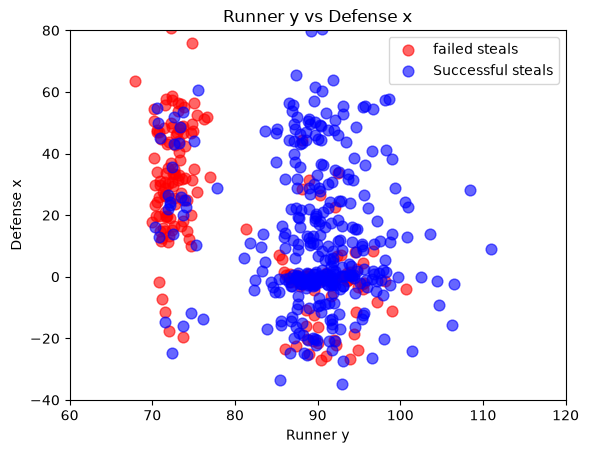

In [505]:
# Establis Figure and Axes
fig, ax = plt.subplots(1, 1)

plot_df = maybe_last_df.select(["runner_y", "defense_x", "steal_successful"]).to_pandas()

# Split steals into success or fail
failed = plot_df[plot_df["steal_successful"] == False]
success = plot_df[plot_df["steal_successful"] == True]

# scatter plot
ax.scatter(failed["runner_y"], failed["defense_x"], color = "red", label = "failed steals", alpha = 0.6, s = 60)
ax.scatter(success["runner_y"], success["defense_x"], color = "blue", label = "Successful steals", alpha = 0.6, s = 60)

# Stablize the X and y axis
ax.set_xlim([60, 120])
ax.set_ylim([-40, 80])

ax.set_xlabel("Runner y")
ax.set_ylabel("Defense x")
ax.set_title("Runner y vs Defense x")

ax.legend()

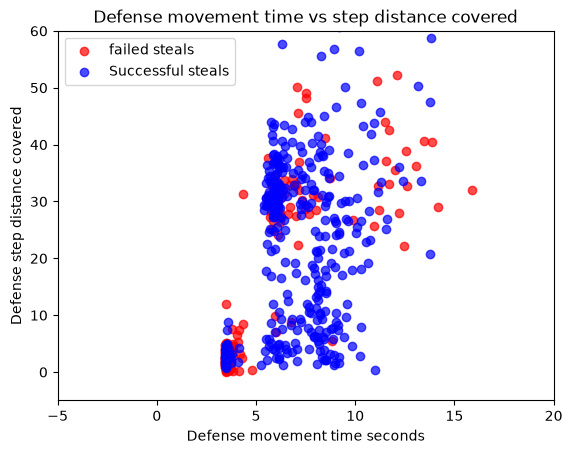

In [506]:
# Establis Figure and Axes
fig, ax = plt.subplots(1, 1)

plot_df = maybe_last_df.select(["change_time_defense_sec", "dcov_step_defense", "steal_successful"]).to_pandas()

# Split steals into success or fail
failed = plot_df[plot_df["steal_successful"] == False]
success = plot_df[plot_df["steal_successful"] == True]

# scatter plot
ax.scatter(failed["change_time_defense_sec"], failed["dcov_step_defense"], color = "red", label = "failed steals", alpha = 0.7)
ax.scatter(success["change_time_defense_sec"], success["dcov_step_defense"], color = "blue", label = "Successful steals", alpha = 0.7)

# Stablize the X and y axis
ax.set_xlim([-5, 20])
ax.set_ylim([-5, 60])

ax.set_xlabel("Defense movement time seconds")
ax.set_ylabel("Defense step distance covered")
ax.set_title("Defense movement time vs step distance covered")

ax.legend()

## Density plot

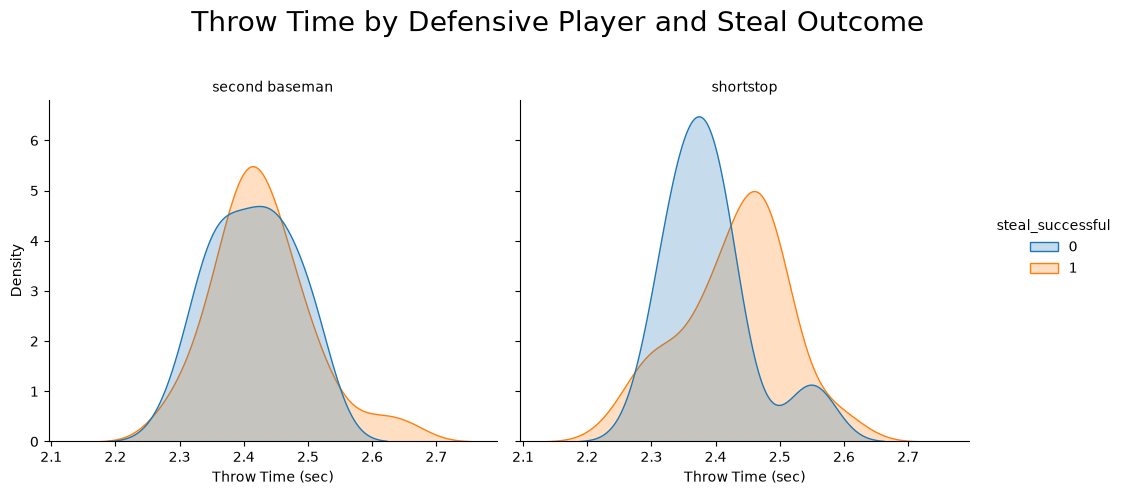

In [507]:
# rename who_caught_it
d_plot = maybe_last_df.to_pandas()
d_plot["who_caught_it"] = d_plot["who_caught_it"].replace({
    "4": "second baseman",
    '0': "no one",
    "6": "shortstop"
})

# remove no one column
d_plot = d_plot[d_plot["who_caught_it"] != "no one"]

# Create a plot
s = sns.displot(
    data = d_plot,
    kind = "kde", # kernel density
    x = "throw_time", # of Exit velocities
    col = "who_caught_it", # Faceted by who caught it
    col_wrap = 2, # 2 plots
    hue = "steal_successful", # split into failed and successful steals
    fill = True, # fill in color
    common_norm = False #  makes the distribution shapes easier to compare
)

s.set_titles("{col_name}")

# add plot title
s.fig.subplots_adjust(top = 0.8)
s.fig.suptitle("Throw Time by Defensive Player and Steal Outcome", fontsize = 20)

s.set(
    xlabel = "Throw Time (sec)",
    ylabel = "Density"
)

## statcast tabel

In [508]:
statcast_table = (
    maybe_last_df
).with_columns(
    pl.col("who_caught_it").replace({
        "4": "second baseman",
        "0": "unknown",
        "6": "short stop"
    }).alias("caught_by")
).group_by(
    "caught_by"
).agg(
    pl.len().alias("plays"),
    pl.col("steal_successful").sum().alias("successful_steals"),
    pl.col("steal_successful").mean().alias("success_rate"),
    pl.col("throw_time").mean().round(2).alias("avg_throw_to_catch_time"),
).with_columns(
    (pl.col("plays") - pl.col("successful_steals")).alias("failed_steals"),
).with_columns(
    (pl.col("success_rate") * 100).round(1).alias("success_rate_percent"),
    (pl.col("failed_steals") / pl.col("plays")).alias("failed_rate"),
    ((pl.col("failed_steals") / pl.col("plays")) * 100).round(1).alias("failed_rate_percent")
).sort(
    ["success_rate_percent"], descending = True
)

In [ ]:
GT(
    statcast_table).tab_header(
        title="Red Light, Green Light",
        subtitle="Steal success by throw"
    ).tab_source_note(
        "0 = failed steal, 1 = successful steal"
    ).cols_label(
        caught_by = "Defensive Player",
        plays = "Plays",
        successful_steals = "Successful Steals",
        success_rate = "Success Rate",
        failed_rate = "Failed Rate",
        avg_throw_to_catch_time = "Avg Throw Time"
    ).cols_hide(
        columns = ["success_rate_percent", "failed_rate_percent", "plays"]
    ).pipe(
        gte.gt_theme_espn
    ).fmt_number(
        columns = "avg_throw_to_catch_time",
        decimals = 2
    ).fmt_percent(
        columns = ["success_rate", "failed_rate"]
    ).cols_align(
        align = "center"
    ).tab_options(
        heading_align="center"
    ).pipe(
        gte.gt_add_divider,
        columns=list(statcast_table.columns),
        color="black",
        sides="all",
        weight=3
    )

# Machine Learning

So what is happening is that all the runnner columns are causing the model to know the answer getting a perfect score of 1.0 which is highly unlikely that we are getting perfect answers. So we are hvaing to redo the model but drop all runner columns

Our orignal features are only adding 1 with a perfect score

Changed it to drop some runnner columns but not all ended up with 6 features but still a perfect 1

droppped all runner columns except position when on 1 base now got 7 features score is 85

dropped all columns related to the runner 4 features score of 75

In [ ]:
runner_cols = [
    "i_accel_runner", "i_vel_runner", "i_jerk_runner",
    "change_time_runner_sec", "dcov_step_runner", "dcov_total_runner",
    "dcov_running_runner", "next_runner_x", "next_runner_y", 
    "runner_x", "runner_y",
    "play_per_game",  "game_string",
    "steal_successful"
]

# 

In [ ]:
# First set random seed
np.random.seed(42)

maybe_last_df = maybe_last_df.to_pandas()

# want to make a copy of df and drop our y steal_successful
x = maybe_last_df.drop(columns = runner_cols)
x = x.select_dtypes(include = "number") # Keep only number_columns
x = x.fillna(0) # Change all nulls to 0 so we dont have to drop them

# our y is what we want to predict so it will be steals
y = maybe_last_df["steal_successful"]

# Split data into training and testing, 70/30
x_train, x_test, y_train, y_test = train_test_split(
    x, y, train_size = .7, test_size = .3,
    stratify = y # makes True/false even data
)

In [ ]:
# SInce we have so many features we are going to use forward selection feature which tests all features for us one at a time
def forward_feature_selection(
        x, y, model, 
        scoring = "roc_auc", # scoring for features (receiver operating characteristic - area under curve)
        cv = 5, # cross validation split 5 times
        max_allowed_score = .9 # sets max score to less than .9
        ):
        chosen_features = [] # Store the features that have been used

        features_left = list(x.columns) # Store the frature that are still available

        cv_scores = [] # store model cv scores

        while len(features_left) > 0: # keep using features until empty
            best_new_feature = None # this will stroe the best feature found
            best_score = float("-inf") # turing score to float
            for new_feature in features_left: 
                features_to_test = chosen_features + [new_feature] # Combine features

                # use cv scores to test model
                score = cross_val_score(
                    model,
                    x[features_to_test],
                    y,
                    scoring = scoring,
                    cv = cv
                ).mean()

                # USe this to save best score while testing
                if score < max_allowed_score and score > best_score:
                    best_score = score
                    best_new_feature = new_feature
            if best_new_feature is None:
                print("no more features bro")
                break

            chosen_features.append(best_new_feature) # Add best one to list

            features_left.remove(best_new_feature) # Remove from test list

            cv_scores.append(best_score) # Save the best score

            print("Added: ", best_new_feature, "| Score: ", best_score)
        
        best_index = np.argmax(cv_scores) # Find best cv score
        best_feature_set = chosen_features[:best_index + 1] # keep only best features
        best_cv_score = cv_scores[best_index] # store the best score
        return chosen_features, cv_scores, best_feature_set, best_cv_score

# Taken from my homework notebook from (Redacted) University this was from Home Work 5 in class (redacted). A copy can be provided if requested

Added:  i_vel_defense | Score:  0.685507326007326
Added:  i_accel_defense | Score:  0.7195850340136054
Added:  dcov_step_defense | Score:  0.7287443746729461
Added:  i_jerk_defense | Score:  0.7339098639455782
Added:  dcov_total_defense | Score:  0.7339098639455782
Added:  dcov_running_defense | Score:  0.7334263474620617
Added:  throw_time | Score:  0.732810962846677
Added:  change_time_defense_sec | Score:  0.7243003663003662
Added:  next_defense_y | Score:  0.7130919675562533
Added:  defense_y | Score:  0.7108836996336997
Added:  defense_x | Score:  0.6938152799581371
Added:  next_defense_x | Score:  0.6904391679748821
Best Features: ['i_vel_defense', 'i_accel_defense', 'dcov_step_defense', 'i_jerk_defense']
Best score: 0.7339098639455782
Number of Features: 4


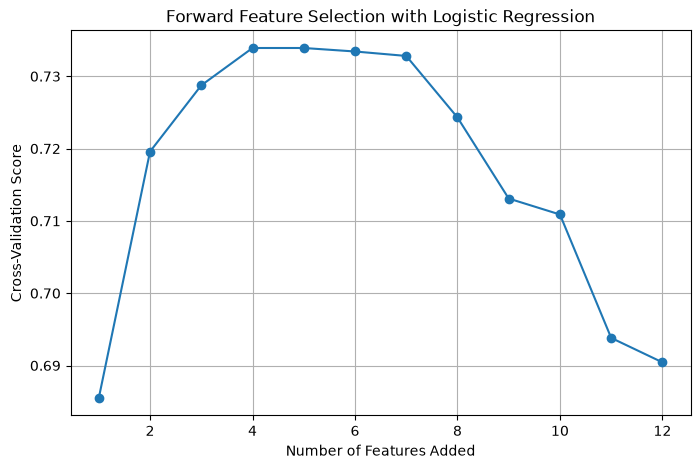

In [ ]:
# Test Feature Selection on LogRegression
log_model = LogisticRegression(max_iter = 10000, class_weight = "balanced")

chosen_features, cv_scores, best_feature_set, best_cv_score = forward_feature_selection(x_train, y_train, log_model, scoring = "roc_auc", cv = 5)


plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cv_scores) + 1), cv_scores, marker="o")
plt.xlabel("Number of Features Added")
plt.ylabel("Cross-Validation Score")
plt.title("Forward Feature Selection with Logistic Regression")
plt.grid(True)

# Best score and number of selected features
best_cv_forward = best_cv_score
num_features_forward = len(best_feature_set)

print("Best Features:", best_feature_set)
print("Best score:", best_cv_forward)
print("Number of Features:", num_features_forward)

In [ ]:
# add a grid search to my trees. What this will do is test different ranges
grid_search = {
    "max_depth": range (1, 20), # tree depth
    "max_leaf_nodes": range(2, 21), # leafs
    "min_samples_leaf": range(1, 10) # nodes in each leaf
}

#  Use my features from the forward selection
x_train_features = x_train[best_feature_set]
x_test_features = x_test[best_feature_set]

# Create my tree
decision_tree = DecisionTreeClassifier(
    random_state = 42,
    class_weight = "balanced"
)

# Use my grid to test the tree
grid = GridSearchCV(
    decision_tree,
    grid_search,
    cv = 5,
    scoring = "roc_auc"
)

# Train my grid
grid.fit(x_train_features, y_train)

# save my best tree
best_tree = grid.best_estimator_

# Print out my info
print("Forward Selection_features: ")
print(best_feature_set)

print()

print("Best Tree Parameters")
print(grid.best_params_)

print()

print("Best CV Score")
print(grid.best_score_)

Forward Selection_features: 
['i_vel_defense', 'i_accel_defense', 'dcov_step_defense', 'i_jerk_defense']

Best Tree Parameters
{'max_depth': 7, 'max_leaf_nodes': 14, 'min_samples_leaf': 9}

Best CV Score
0.7770757456828886


In [ ]:
read_tree = export_text(
    best_tree, feature_names = list(x_train_features.columns)
)

print(read_tree)

|--- dcov_step_defense <= 3.88
|   |--- i_jerk_defense <= 0.03
|   |   |--- dcov_step_defense <= 1.21
|   |   |   |--- class: 0
|   |   |--- dcov_step_defense >  1.21
|   |   |   |--- class: 1
|   |--- i_jerk_defense >  0.03
|   |   |--- class: 0
|--- dcov_step_defense >  3.88
|   |--- i_jerk_defense <= 0.15
|   |   |--- i_jerk_defense <= 0.05
|   |   |   |--- dcov_step_defense <= 35.00
|   |   |   |   |--- i_vel_defense <= 0.66
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- i_vel_defense >  0.66
|   |   |   |   |   |--- class: 1
|   |   |   |--- dcov_step_defense >  35.00
|   |   |   |   |--- i_vel_defense <= 3.82
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- i_vel_defense >  3.82
|   |   |   |   |   |--- class: 1
|   |   |--- i_jerk_defense >  0.05
|   |   |   |--- i_accel_defense <= 0.48
|   |   |   |   |--- class: 0
|   |   |   |--- i_accel_defense >  0.48
|   |   |   |   |--- i_jerk_defense <= 0.09
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- i_jerk_defe

In [ ]:
# Now we test are features on the decision tree to see which one is best

# predict if steal or not
y_pred = best_tree.predict(x_test_features)

# See the scores
print("Accuracy: ", accuracy_score(y_test, y_pred))

Accuracy:  0.7421383647798742


Some Tests we ran earlier to try and find the best model

I decided to go with test 1 because it had no runner columns and because test 2 and 3 have the same score

| test_# | #_of_features | features_list | tree_depth | leaf_nodes | min_leafs | train_score | test_score | Notes |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 4 | ['i_vel_defense', 'i_accel_defense', 'dcov_step_defense', 'i_jerk_defense'] | 7 | 14 | 9 | 77% | 74% | dropped all runner cols |
| 2 | 7 | ['runner_y', 'runner_x', 'throw_time', 'change_time_defense_sec', 'i_jerk_defense', 'defense_y', 'dcov_step_defense'] | 5 | 8 | 7 | 84% | 82% | left in runner positions |
| 3 | 6 | ['runner_y', 'runner_x', 'throw_time', 'i_accel_runner', 'change_time_defense_sec', 'dcov_step_defense'] | 5 | 8 | 7 | 84% | 82% | left in all runner cols |
| 4 | 4 | ['runner_y', 'i_vel_runner', 'runner_x', 'dcov_step_defense'] | 1 | 2 | 1 | 100% | 100% | removed max score and added in all columns|